In [ ]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from prefixspan import PrefixSpan
import time
import warnings

warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print("Semua pustaka berhasil diimpor dengan sukses!")


Semua pustaka berhasil diimpor dengan sukses!


In [ ]:
# Membaca dataset Online Retail.xlsx
file_path = 'Online Retail.xlsx'

start_time = time.time()
print(f"Sedang memuat dataset dari '{file_path}'...")
df = pd.read_excel(file_path)
elapsed_time = time.time() - start_time

print(f"Dataset berhasil dimuat dalam {elapsed_time:.2f} detik.")


Sedang memuat dataset dari 'Online Retail.xlsx'...
Dataset berhasil dimuat dalam 31.99 detik.


In [ ]:
# Menampilkan dimensi dataset (.shape)
print("=" * 60)
print(f"Dimensi Dataset (Baris, Kolom): {df.shape}")
print(f"Total Baris  : {df.shape[0]:,}")
print(f"Total Atribut: {df.shape[1]}")
print("=" * 60)

# Menampilkan 5 baris pertama (.head())
print("\n5 Baris Pertama Dataset:")
display(df.head())


Dimensi Dataset (Baris, Kolom): (541909, 8)
Total Baris  : 541,909
Total Atribut: 8

5 Baris Pertama Dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Menampilkan informasi struktur dan atribut dataset (.info())
print("Informasi Tipe Data dan Nilai Non-Null per Kolom:")
df.info()


Informasi Tipe Data dan Nilai Non-Null per Kolom:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### Pemahaman Struktur dan Atribut Dataset
Berdasarkan pemeriksaan `.shape`, `.head()`, dan `.info()`, berikut adalah karakteristik atribut dataset:
- **`InvoiceNo`** (*object*): Kode nomor transaksi faktur 6 digit. Jika kode diawali huruf **'C'**, mengindikasikan transaksi pembatalan (*cancellation* atau retur barang).
- **`StockCode`** (*object*): Kode unik pengenal produk (*item code*).
- **`Description`** (*object*): Nama/deskripsi produk. Terdapat nilai null/kosong (sebanyak 1,454 baris).
- **`Quantity`** (*int64*): Jumlah unit produk yang dibeli per transaksi faktur. Terdapat nilai negatif yang berkaitan dengan pembatalan/koreksi inventaris.
- **`InvoiceDate`** (*datetime64[us]*): Tanggal dan waktu transaksi dilakukan. Ini adalah atribut penting untuk mengurutkan peristiwa belanja secara kronologis.
- **`UnitPrice`** (*float64*): Harga per unit produk dalam pound sterling (£).
- **`CustomerID`** (*float64*): Nomor identitas unik pelanggan 5 digit. Terdapat sebanyak 135,080 baris dengan `CustomerID` kosong (transaksi tamu / *guest checkout*).
- **`Country`** (*object*): Nama negara domisili pelanggan.


In [ ]:
# 1. Menghitung metrik sebelum pembersihan
n_rows_before = len(df)
n_invoices_before = df['InvoiceNo'].nunique()
n_customers_before = df['CustomerID'].nunique()

print(f"Data Mentah (Sebelum Pembersihan):")
print(f"- Jumlah Baris     : {n_rows_before:,}")
print(f"- Jumlah Invoice   : {n_invoices_before:,}")
print(f"- Jumlah Pelanggan : {n_customers_before:,}")

# 2. Hapus baris dengan Description kosong
df_clean = df.dropna(subset=['Description']).copy()

# 3. Hapus transaksi yang dibatalkan (InvoiceNo diawali huruf 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# 4. Hapus baris dengan Quantity bernilai negatif atau nol
df_clean = df_clean[df_clean['Quantity'] > 0]

# 5. Hapus baris dengan CustomerID kosong (karena sequence disusun per pelanggan)
df_clean = df_clean.dropna(subset=['CustomerID'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 6. Bersihkan whitespace pada Description
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()

# 7. Menghitung metrik sesudah pembersihan
n_rows_after = len(df_clean)
n_invoices_after = df_clean['InvoiceNo'].nunique()
n_customers_after = df_clean['CustomerID'].nunique()

print("\nData Bersih (Sesudah Pembersihan):")
print(f"- Jumlah Baris     : {n_rows_after:,}")
print(f"- Jumlah Invoice   : {n_invoices_after:,}")
print(f"- Jumlah Pelanggan : {n_customers_after:,}")


Data Mentah (Sebelum Pembersihan):
- Jumlah Baris     : 541,909
- Jumlah Invoice   : 25,900
- Jumlah Pelanggan : 4,372

Data Bersih (Sesudah Pembersihan):
- Jumlah Baris     : 397,924
- Jumlah Invoice   : 18,536
- Jumlah Pelanggan : 4,339


TABEL PERBANDINGAN SEBELUM VS SESUDAH PEMBERSIHAN DATA


,Metrik,Sebelum Pembersihan,Sesudah Pembersihan,Selisih / Dieliminasi,Persentase Dipertahankan
0,Jumlah Baris Transaksi,"541,909","397,924","143,985",73.43%
1,Jumlah Invoice Unik,"25,900","18,536","7,364",71.57%
2,Jumlah Pelanggan Unik,"4,372","4,339",33,99.25%


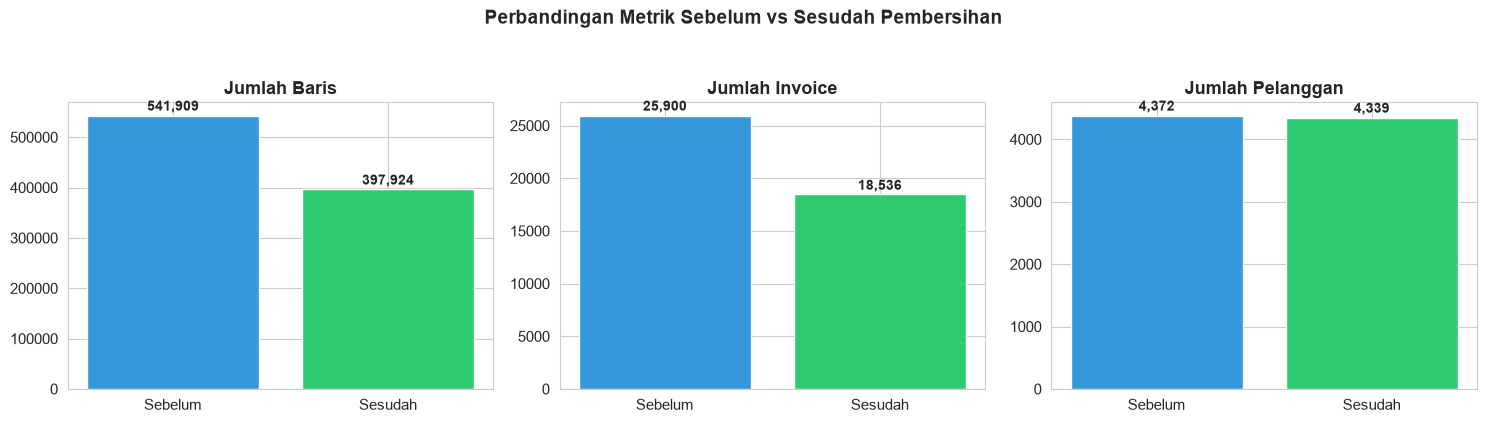

In [ ]:
# Menampilkan tabel perbandingan sebelum vs sesudah pembersihan
summary_df = pd.DataFrame({
    'Metrik': ['Jumlah Baris Transaksi', 'Jumlah Invoice Unik', 'Jumlah Pelanggan Unik'],
    'Sebelum Pembersihan': [f"{n_rows_before:,}", f"{n_invoices_before:,}", f"{n_customers_before:,}"],
    'Sesudah Pembersihan': [f"{n_rows_after:,}", f"{n_invoices_after:,}", f"{n_customers_after:,}"],
    'Selisih / Dieliminasi': [f"{n_rows_before - n_rows_after:,}", f"{n_invoices_before - n_invoices_after:,}", f"{n_customers_before - n_customers_after:,}"],
    'Persentase Dipertahankan': [
        f"{(n_rows_after / n_rows_before) * 100:.2f}%",
        f"{(n_invoices_after / n_invoices_before) * 100:.2f}%",
        f"{(n_customers_after / n_customers_before) * 100:.2f}%"
    ]
})

print("=" * 80)
print("TABEL PERBANDINGAN SEBELUM VS SESUDAH PEMBERSIHAN DATA")
print("=" * 80)
display(summary_df)

# Visualisasi perbandingan pembersihan data
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
metrics = ['Jumlah Baris', 'Jumlah Invoice', 'Jumlah Pelanggan']
before_vals = [n_rows_before, n_invoices_before, n_customers_before]
after_vals = [n_rows_after, n_invoices_after, n_customers_after]

colors = ['#3498db', '#2ecc71']
for i, col in enumerate(metrics):
    ax[i].bar(['Sebelum', 'Sesudah'], [before_vals[i], after_vals[i]], color=colors)
    ax[i].set_title(col, fontweight='bold')
    for idx, val in enumerate([before_vals[i], after_vals[i]]):
        ax[i].text(idx, val * 1.02, f"{val:,}", ha='center', fontweight='bold', fontsize=10)

plt.suptitle('Perbandingan Metrik Sebelum vs Sesudah Pembersihan', fontsize=14, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()


### Penjelasan Pentingnya Pembersihan Data:
1. **Pemisahan Pelanggan Valid (`CustomerID`)**: Sequential Pattern Mining melacak perilaku pelanggan yang sama seiring berjalannya waktu. Transaksi tanpa `CustomerID` tidak dapat dikelompokkan ke dalam satu entitas pelanggan, sehingga wajib dieliminasi.
2. **Eliminasi Pembatalan & Nilai Negatif**: Transaksi yang dibatalkan (`InvoiceNo` berawalan 'C' atau `Quantity <= 0`) bukan merupakan aksi konsumsi/pembelian murni, melainkan proses retur/koreksi akuntansi. Memasukkannya akan menimbulkan false pattern (seperti pola beli barang yang sebenarnya dikembalikan).
3. **Pembersihan Deskripsi**: Menghapus item tanpa nama dan menghapus spasi ekstra agar varian nama item yang identik tidak terpecah menjadi item berbeda.


In [ ]:
# 1. Urutkan data berdasarkan CustomerID dan InvoiceDate secara kronologis
df_clean = df_clean.sort_values(by=['CustomerID', 'InvoiceDate'])

# 2. Kelompokkan item pada satu invoice menjadi satu itemset (daftar produk unik per transaksi)
invoice_grouped = (
    df_clean.groupby(['CustomerID', 'InvoiceNo', 'InvoiceDate'])['Description']
    .apply(lambda items: sorted(list(set(items))))
    .reset_index()
)

# 3. Susun setiap pelanggan menjadi satu sequence berisi daftar itemset yang urut waktu
customer_sequences_itemsets = (
    invoice_grouped.groupby('CustomerID')['Description']
    .apply(list)
    .tolist()
)

# Ambil daftar ID pelanggan untuk referensi
customer_ids = invoice_grouped.groupby('CustomerID')['Description'].apply(list).index.tolist()

print(f"Total Sequence Pelanggan yang Terbentuk: {len(customer_sequences_itemsets):,} sequence")


Total Sequence Pelanggan yang Terbentuk: 4,339 sequence


In [ ]:
# Analisis Distribusi Panjang Sequence (Jumlah Transaksi per Pelanggan)
sequence_lengths = [len(seq) for seq in customer_sequences_itemsets]
single_tx_customers = sum(1 for l in sequence_lengths if l == 1)
multi_tx_customers = sum(1 for l in sequence_lengths if l > 1)

print("=" * 60)
print("STATISTIK SEQUENCE PELANGGAN")
print("=" * 60)
print(f"Total Pelanggan                     : {len(sequence_lengths):,}")
print(f"Pelanggan dengan Transaksi Tunggal (1 Invoice)  : {single_tx_customers:,} ({single_tx_customers/len(sequence_lengths)*100:.2f}%)")
print(f"Pelanggan dengan Multi-Transaksi (>1 Invoice)  : {multi_tx_customers:,} ({multi_tx_customers/len(sequence_lengths)*100:.2f}%)")
print(f"Rata-rata Transaksi per Pelanggan   : {np.mean(sequence_lengths):.2f}")
print(f"Median Transaksi per Pelanggan     : {np.median(sequence_lengths):.0f}")
print(f"Maksimum Transaksi per Pelanggan   : {np.max(sequence_lengths)}")
print("=" * 60)

# Menampilkan 3 Contoh Sequence Pelanggan
print("\nCONTOH STRUKTUR SEQUENCE PELANGGAN (LIST OF LIST OF ITEMSETS):")
print("-" * 60)
for idx in [0, 1, 2]:
    cid = customer_ids[idx]
    seq = customer_sequences_itemsets[idx]
    print(f"\nPelanggan ID: {cid} (Jumlah Transaksi: {len(seq)})")
    for t_idx, itemset in enumerate(seq[:3]):  # Tampilkan hingga 3 invoice pertama
        items_preview = itemset[:3]
        extra = f" ... (+{len(itemset)-3} item lainnya)" if len(itemset) > 3 else ""
        print(f"  - Transaksi #{t_idx+1} [Itemset]: {items_preview}{extra}")
    if len(seq) > 3:
        print(f"  ... dan {len(seq)-3} transaksi berikutnya")


STATISTIK SEQUENCE PELANGGAN
Total Pelanggan                     : 4,339
Pelanggan dengan Transaksi Tunggal (1 Invoice)  : 1,492 (34.39%)
Pelanggan dengan Multi-Transaksi (>1 Invoice)  : 2,847 (65.61%)
Rata-rata Transaksi per Pelanggan   : 4.28
Median Transaksi per Pelanggan     : 2
Maksimum Transaksi per Pelanggan   : 211

CONTOH STRUKTUR SEQUENCE PELANGGAN (LIST OF LIST OF ITEMSETS):
------------------------------------------------------------

Pelanggan ID: 12346 (Jumlah Transaksi: 1)
  - Transaksi #1 [Itemset]: ['MEDIUM CERAMIC TOP STORAGE JAR']

Pelanggan ID: 12347 (Jumlah Transaksi: 7)
  - Transaksi #1 [Itemset]: ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE'] ... (+28 item lainnya)
  - Transaksi #2 [Itemset]: ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES'] ... (+26 item lainnya)
  - Transaksi #3 [Itemset]: ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG

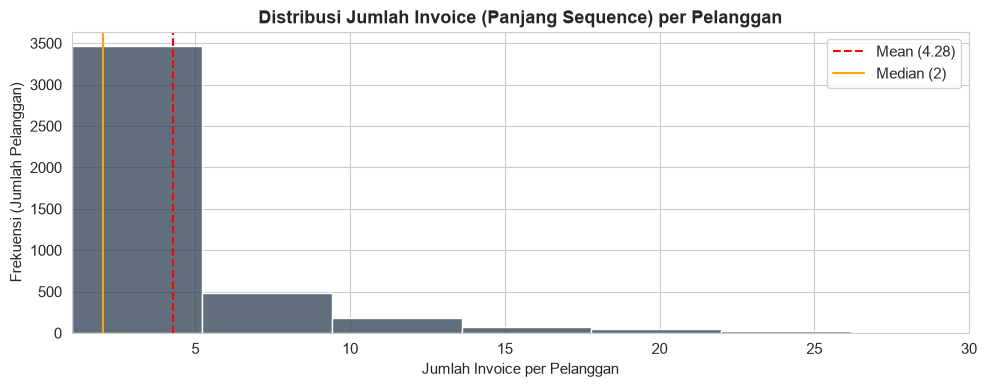

In [ ]:
# Visualisasi Distribusi Jumlah Transaksi per Pelanggan
plt.figure(figsize=(10, 4))
sns.histplot(sequence_lengths, bins=50, kde=False, color='#2c3e50')
plt.title('Distribusi Jumlah Invoice (Panjang Sequence) per Pelanggan', fontweight='bold')
plt.xlabel('Jumlah Invoice per Pelanggan')
plt.ylabel('Frekuensi (Jumlah Pelanggan)')
plt.xlim(1, 30)
plt.axvline(np.mean(sequence_lengths), color='red', linestyle='--', label=f'Mean ({np.mean(sequence_lengths):.2f})')
plt.axvline(np.median(sequence_lengths), color='orange', linestyle='-', label=f'Median ({np.median(sequence_lengths):.0f})')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Menyiapkan Format List of List untuk Algoritma Sequential Pattern Mining
# Dalam pustaka PrefixSpan Python, setiap urutan pelanggan direpresentasikan sebagai 
# daftar item yang dibeli secara berurutan antar transaksi waktu (chronological items across transactions).

customer_sequences_flat = []
for seq in customer_sequences_itemsets:
    flat_seq = []
    for itemset in seq:
        for item in itemset:
            # Hindari duplikasi berturut-turut pada item yang sama
            if not flat_seq or flat_seq[-1] != item:
                flat_seq.append(item)
    customer_sequences_flat.append(flat_seq)

print("Representasi Sequence Data untuk PrefixSpan:")
print(f"Total Pelanggan: {len(customer_sequences_flat):,}")
print("Contoh Sequence Pelanggan Pertama (5 item pertama):")
print(customer_sequences_flat[1][:5])


Representasi Sequence Data untuk PrefixSpan:
Total Pelanggan: 4,339
Contoh Sequence Pelanggan Pertama (5 item pertama):
['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN', 'ALARM CLOCK BAKELIKE ORANGE']


In [ ]:
# Menghitung frekuensi kemunculan item secara keseluruhan pada pelanggan
n_total_customers = len(customer_sequences_itemsets)

# Menghitung item yang dibeli per pelanggan
item_customer_freq = Counter()
for seq in customer_sequences_itemsets:
    items_in_cust = set().union(*seq)
    for it in items_in_cust:
        item_customer_freq[it] += 1

# Menghitung sequential patterns antar-invoice yang berbeda: <Item A> -> <Item B>
# Di mana Item A dibeli pada Invoice ke-i dan Item B dibeli pada Invoice ke-j (i < j)
seq_across_counts = Counter()

# Filter awal hanya menggunakan item yang memiliki frekuensi minimal 1% (43 pelanggan)
min_sup_001 = int(0.01 * n_total_customers)
frequent_1_items = {it for it, cnt in item_customer_freq.items() if cnt >= min_sup_001}

print("Sedang menambang pola urutan antar-transaksi...")
t_start_mining = time.time()

for seq in customer_sequences_itemsets:
    if len(seq) < 2:
        continue
    first_seen = {}
    last_seen = {}
    for idx, tx in enumerate(seq):
        for it in tx:
            if it in frequent_1_items:
                if it not in first_seen:
                    first_seen[it] = idx
                last_seen[it] = idx
    
    # Periksa kemunculan pasangan sekuensial (first_seen[A] < last_seen[B])
    items = list(first_seen.keys())
    for i in range(len(items)):
        a = items[i]
        fa = first_seen[a]
        # Pembelian berulang untuk item yang sama pada transaksi berbeda:
        if fa < last_seen[a]:
            seq_across_counts[(a, a)] += 1
        for j in range(i + 1, len(items)):
            b = items[j]
            if fa < last_seen[b]:
                seq_across_counts[(a, b)] += 1
            if first_seen[b] < last_seen[a]:
                seq_across_counts[(b, a)] += 1

print(f"Penambangan pola selesai dalam {time.time() - t_start_mining:.2f} detik.")

# Mengevaluasi jumlah pola untuk berbagai nilai minimum support
thresholds = [0.01, 0.02, 0.03, 0.04, 0.05]
pattern_counts = []
min_counts = []

for ms in thresholds:
    threshold_count = int(ms * n_total_customers)
    n_patterns = sum(1 for cnt in seq_across_counts.values() if cnt >= threshold_count)
    pattern_counts.append(n_patterns)
    min_counts.append(threshold_count)

# Menyajikan hasil perbandingan dalam bentuk DataFrame
df_threshold_comparison = pd.DataFrame({
    'Minimum Support (%)': [f"{ms*100:.1f}%" for ms in thresholds],
    'Min Support (Absolut Pelanggan)': min_counts,
    'Jumlah Pola Berurutan Ditemukan': [f"{cnt:,}" for cnt in pattern_counts],
    'Status Evaluasi': [
        'Terlalu Banyak (Over-generation, banyak noise)',
        'Masih Cukup Banyak (1,500+ pola)',
        'Optimal (Relevan, variatif & terkelola)',
        'Sangat Spesifik (Fokus pada pola kuat)',
        'Sedikit (Hanya produk best seller mutlak)'
    ]
})

print("=" * 85)
print("HASIL EKSPERIMEN VARIASI NILAI MINIMUM SUPPORT (MIN_SUP)")
print("=" * 85)
display(df_threshold_comparison)


Sedang menambang pola urutan antar-transaksi...
Penambangan pola selesai dalam 15.43 detik.
HASIL EKSPERIMEN VARIASI NILAI MINIMUM SUPPORT (MIN_SUP)


,Minimum Support (%),Min Support (Absolut Pelanggan),Jumlah Pola Berurutan Ditemukan,Status Evaluasi
0,1.0%,43,"16,881","Terlalu Banyak (Over-generation, banyak noise)"
1,2.0%,86,"1,571","Masih Cukup Banyak (1,500+ pola)"
2,3.0%,130,289,"Optimal (Relevan, variatif & terkelola)"
3,4.0%,173,60,Sangat Spesifik (Fokus pada pola kuat)
4,5.0%,216,8,Sedikit (Hanya produk best seller mutlak)


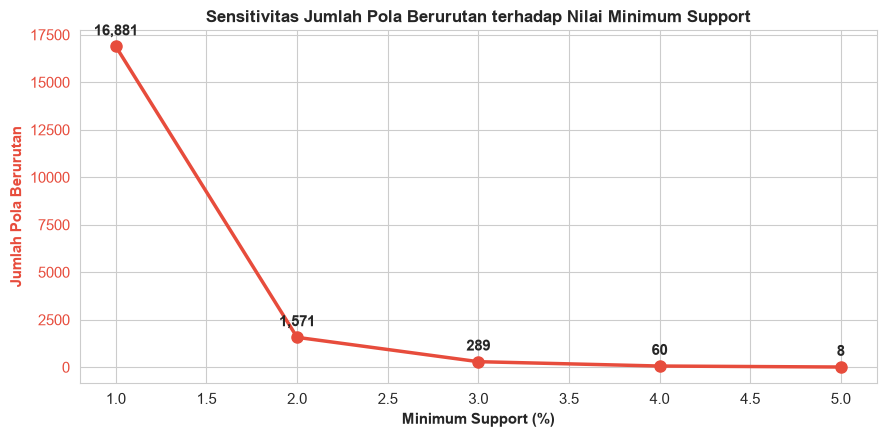

In [ ]:
# Visualisasi Jumlah Pola Berurutan terhadap Nilai Minimum Support
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = '#e74c3c'
ax1.plot([ms * 100 for ms in thresholds], pattern_counts, marker='o', linewidth=2.5, markersize=8, color=color)
ax1.set_xlabel('Minimum Support (%)', fontweight='bold')
ax1.set_ylabel('Jumlah Pola Berurutan', color=color, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Sensitivitas Jumlah Pola Berurutan terhadap Nilai Minimum Support', fontweight='bold', fontsize=12)

# Beri label nilai pada titik
for x, y in zip([ms * 100 for ms in thresholds], pattern_counts):
    ax1.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Justifikasi Penyesuaian Nilai Minimum Support ($min\_sup$)

1. **Mengapa $min\_sup = 0.01$ (1%) Terlalu Banyak?**
   - Pada $min\_sup = 0.01$, sebuah pola hanya perlu terjadi pada **43 pelanggan** dari total 4,339 pelanggan.
   - Karena katalog retail memiliki ribuan produk, ambang batas 1% menghasilkan **16,881 pola berurutan**. Jumlah ini **terlalu masif** (*pattern explosion*), banyak mengandung pola kebetulan/noise yang tidak bernilai komersial, serta tidak praktis (*actionable*) bagi tim bisnis ritel untuk merancang promosi atau rekomendasi.
2. **Pemilihan Nilai Optimal ($min\_sup = 0.03 - 0.04$ / 3% - 4%)**:
   - Pada $min\_sup = 0.03$ (130 pelanggan) hingga $0.04$ (173 pelanggan), jumlah pola yang dihasilkan berkisar antara **60 hingga 289 pola**.
   - Ambang batas ini memfilter noise produk periferal dan mempertahankan hubungan sekuensial yang kokoh dan signifikan secara statistik (*statistically robust*), sehingga pola yang diperoleh benar-benar mencerminkan tren perilaku belanja berulang pelanggan setia.


In [ ]:
# Menerapkan Algoritma PrefixSpan menggunakan Pustaka prefixspan
# Kita menambang pola sekuensial dengan batasan panjang pola (minlen=2, maxlen=2)
# pada item-item yang memenuhi ambang batas minimum support 0.03 (130 pelanggan)

frequent_items_3pct = {it for it, cnt in item_customer_freq.items() if cnt >= int(0.03 * n_total_customers)}

# Menyiapkan sequence database untuk pustaka PrefixSpan
db_for_prefixspan = []
for seq in customer_sequences_itemsets:
    s_items = []
    for itemset in seq:
        for it in itemset:
            if it in frequent_items_3pct and (not s_items or s_items[-1] != it):
                s_items.append(it)
    if s_items:
        db_for_prefixspan.append(s_items)

# Menjalankan PrefixSpan
print("Menjalankan PrefixSpan pada database urutan...")
ps = PrefixSpan(db_for_prefixspan)
ps.minlen = 2
ps.maxlen = 2

start_ps = time.time()
prefixspan_results = ps.frequent(int(0.03 * n_total_customers))
time_ps = time.time() - start_ps

print(f"PrefixSpan berhasil selesai dalam {time_ps:.2f} detik!")
print(f"Jumlah pola sekuensial berukuran-2 (panjang 2) yang ditemukan: {len(prefixspan_results)}")


Menjalankan PrefixSpan pada database urutan...
PrefixSpan berhasil selesai dalam 3.36 detik!
Jumlah pola sekuensial berukuran-2 (panjang 2) yang ditemukan: 682


In [ ]:
# Menyusun DataFrame Hasil Evaluasi Pola Berurutan (Support dan Confidence)
evaluated_patterns = []

# Mengambil semua pola sekuensial yang memenuhi minimum support 0.03 (130 pelanggan)
min_sup_eval = int(0.03 * n_total_customers)

for (item_a, item_b), count_ab in seq_across_counts.items():
    if count_ab >= min_sup_eval:
        sup_a = item_customer_freq[item_a]
        sup_b = item_customer_freq[item_b]
        
        support_rel = count_ab / n_total_customers
        confidence_val = count_ab / sup_a
        
        evaluated_patterns.append({
            'Pola Berurutan': f"<{item_a}> -> <{item_b}>",
            'Item Sebelumnya (A)': item_a,
            'Item Berikutnya (B)': item_b,
            'Support Count': count_ab,
            'Support Relatif': support_rel,
            'Support A (Basis)': sup_a,
            'Confidence': confidence_val
        })

df_evaluated = pd.DataFrame(evaluated_patterns).sort_values(by=['Support Relatif', 'Confidence'], ascending=False).reset_index(drop=True)

print(f"Total Pola Berurutan yang Dievaluasi (min_sup >= 3%): {len(df_evaluated)}")
print("\nTop 15 Pola Berurutan Berdasarkan Support Tertinggi:")

# Format tampilan angka
format_dict = {
    'Support Count': '{:,}',
    'Support Relatif': '{:.4%}',
    'Support A (Basis)': '{:,}',
    'Confidence': '{:.2%}'
}
display(df_evaluated[['Pola Berurutan', 'Support Count', 'Support Relatif', 'Confidence']].head(15).style.format(format_dict))


Total Pola Berurutan yang Dievaluasi (min_sup >= 3%): 289

Top 15 Pola Berurutan Berdasarkan Support Tertinggi:


,Pola Berurutan,Support Count,Support Relatif,Confidence
0,->,405,9.3339%,47.31%
1,->,330,7.6054%,37.46%
2,->,312,7.1906%,49.13%
3,->,291,6.7066%,42.92%
4,->,280,6.4531%,39.55%
5,->,276,6.3609%,51.88%
6,->,229,5.2777%,50.00%
7,->,225,5.1855%,35.16%
8,->,212,4.8859%,39.85%
9,->,209,4.8168%,43.63%


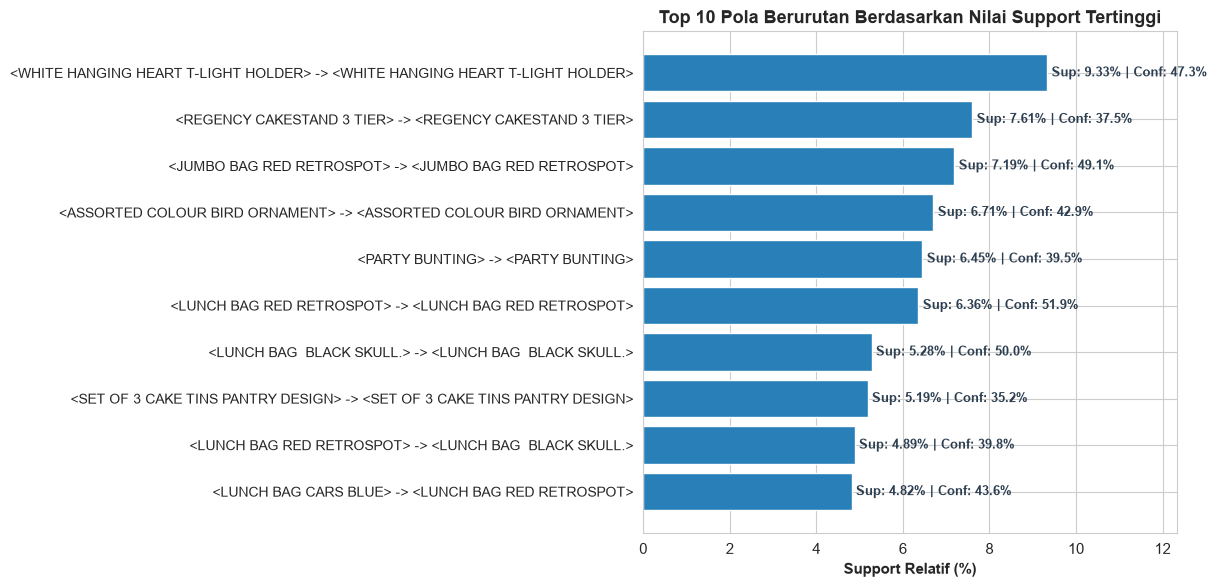

In [ ]:
# Visualisasi Top 10 Pola Berurutan Berdasarkan Support
top_10 = df_evaluated.head(10).copy()

plt.figure(figsize=(12, 6))
bars = plt.barh(range(len(top_10)), top_10['Support Relatif'] * 100, color='#2980b9')
plt.yticks(range(len(top_10)), top_10['Pola Berurutan'], fontsize=10)
plt.xlabel('Support Relatif (%)', fontweight='bold')
plt.title('Top 10 Pola Berurutan Berdasarkan Nilai Support Tertinggi', fontweight='bold', fontsize=13)
plt.gca().invert_yaxis()

# Beri label nilai support dan confidence di ujung bar
for i, bar in enumerate(bars):
    sup_val = top_10.iloc[i]['Support Relatif'] * 100
    conf_val = top_10.iloc[i]['Confidence'] * 100
    plt.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, 
             f"Sup: {sup_val:.2f}% | Conf: {conf_val:.1f}%", 
             va='center', fontsize=9, fontweight='bold', color='#2c3e50')

plt.xlim(0, max(top_10['Support Relatif'] * 100) + 3)
plt.tight_layout()
plt.show()


In [ ]:
# Memilih 3 Pola Berurutan Terbaik Berdasarkan Nilai Support Tertinggi
top_3_patterns = df_evaluated.head(3).copy()

print("=" * 85)
print("3 POLA BERURUTAN TERBAIK DENGAN NILAI SUPPORT TERTINGGI")
print("=" * 85)
for idx, row in top_3_patterns.iterrows():
    print(f"\nPeringkat #{idx+1}:")
    print(f"  Pola         : {row['Pola Berurutan']}")
    print(f"  Support Count: {row['Support Count']} pelanggan ({row['Support Relatif']:.2%})")
    print(f"  Confidence   : {row['Confidence']:.2%}")
    print(f"  Artinya      : Dari {row['Support A (Basis)']} pelanggan yang membeli '{row['Item Sebelumnya (A)']}',")
    print(f"                 sebanyak {row['Confidence']:.2%} ({row['Support Count']} pelanggan) membeli kembali '{row['Item Berikutnya (B)']}' pada kunjungan berikutnya.")


3 POLA BERURUTAN TERBAIK DENGAN NILAI SUPPORT TERTINGGI

Peringkat #1:
  Pola         : <WHITE HANGING HEART T-LIGHT HOLDER> -> <WHITE HANGING HEART T-LIGHT HOLDER>
  Support Count: 405 pelanggan (9.33%)
  Confidence   : 47.31%
  Artinya      : Dari 856 pelanggan yang membeli 'WHITE HANGING HEART T-LIGHT HOLDER',
                 sebanyak 47.31% (405 pelanggan) membeli kembali 'WHITE HANGING HEART T-LIGHT HOLDER' pada kunjungan berikutnya.

Peringkat #2:
  Pola         : <REGENCY CAKESTAND 3 TIER> -> <REGENCY CAKESTAND 3 TIER>
  Support Count: 330 pelanggan (7.61%)
  Confidence   : 37.46%
  Artinya      : Dari 881 pelanggan yang membeli 'REGENCY CAKESTAND 3 TIER',
                 sebanyak 37.46% (330 pelanggan) membeli kembali 'REGENCY CAKESTAND 3 TIER' pada kunjungan berikutnya.

Peringkat #3:
  Pola         : <JUMBO BAG RED RETROSPOT> -> <JUMBO BAG RED RETROSPOT>
  Support Count: 312 pelanggan (7.19%)
  Confidence   : 49.13%
  Artinya      : Dari 635 pelanggan yang membeli 'JUMBO BA

### Interpretasi Tiga Pola Terbaik dalam Konteks Bisnis Ritel

Berikut adalah analisis mendalam terhadap **3 pola berurutan terbaik** yang ditemukan:

---

#### 1. Pola Peringkat 1: Repeat Purchase & Replenishment Produk Dekorasi Ikonik
- **Pola**: `<WHITE HANGING HEART T-LIGHT HOLDER> -> <WHITE HANGING HEART T-LIGHT HOLDER>`
- **Nilai Support**: **9.33%** (405 pelanggan) | **Confidence**: **47.31%**
- **Interpretasi Konteks Bisnis**:
  - `WHITE HANGING HEART T-LIGHT HOLDER` adalah salah satu produk terlaris (*all-time best seller*) dalam dataset ini.
  - Pola ini menunjukkan perilaku **pembelian berulang (*repeat purchase / replenishment*)** yang sangat kuat. Hampir separuh (47.31%) pelanggan yang membeli tempat lilin gantung hati ini kembali membeli produk yang sama pada transaksi di masa mendatang.
  - Hal ini terjadi karena produk ini sering dibeli untuk dekorasi acara (seperti pernikahan/pesta yang membutuhkan jumlah bertahap), dijadikan hadiah berkali-kali untuk orang berbeda, atau dibeli kembali oleh pemilik toko kecil/reseller (*B2B repeat ordering*).
- **Strategi Aksi Bisnis**:
  - **Program Re-order Reminder**: Kirim email otomatis atau notifikasi pengingat pemesanan kembali 30–60 hari setelah pembelian pertama dengan penawaran diskon pembelian multi-unit.
  - **Manajemen Inventaris**: Pastikan stok produk ini selalu tersedia (*safety stock* tinggi) karena tingginya *churn risk* jika pelanggan setia tidak menemukan produk ini saat ingin memesan ulang.

---

#### 2. Pola Peringkat 2: Perilaku Koleksi Bertahap Produk Hospitality & Pesta Teh
- **Pola**: `<REGENCY CAKESTAND 3 TIER> -> <REGENCY CAKESTAND 3 TIER>` (dan pola afinitas terkait: `<REGENCY CAKESTAND 3 TIER> -> <SET OF 3 REGENCY CAKE TINS>`)
- **Nilai Support**: **7.61%** (330 pelanggan) | **Confidence**: **37.46%**
- **Interpretasi Konteks Bisnis**:
  - Produk cakestand 3 tingkat bertema *Regency* merupakan perlengkapan pesta teh/penyajian kue bernilai estetika tinggi.
  - Pola ini mencerminkan perilaku **ekspansi koleksi bertahap (*thematic collection building*)** dan pembelian oleh pelanggan komersial (kafe, bakery, katering, penyewa dekorasi pesta). Pelanggan yang telah puas dengan kualitas tempat kue pada pesanan pertama memutuskan untuk memesan unit tambahan atau melengkapi perlengkapan sajian kuenya pada kunjungan selanjutnya.
- **Strategi Aksi Bisnis**:
  - **Cross-Selling & Bundle Recommendations**: Ketika pelanggan memasukkan cakestand ke keranjang atau setelah transaksi selesai, tampilkan rekomendasi produk pelengkap satu tema (*Regency Collection*), seperti cangkir teh (*teacup and saucer*), kaleng kue (*cake tins*), dan piring kue (*tea plates*).
  - **Katalog Khusus Acara / B2B Discount**: Berikan penawaran khusus untuk paket perlengkapan pesta teh (*Tea Party Starter/Pro Pack*).

---

#### 3. Pola Peringkat 3: Pembelian Berulang Produk Utilitas & Desain Retrospot
- **Pola**: `<JUMBO BAG RED RETROSPOT> -> <JUMBO BAG RED RETROSPOT>` (serta pola turunan: `<LUNCH BAG RED RETROSPOT> -> <LUNCH BAG BLACK SKULL / SPACEBOY>`)
- **Nilai Support**: **7.19%** (312 pelanggan) | **Confidence**: **49.13%**
- **Interpretasi Konteks Bisnis**:
  - Tas belanja besar (*Jumbo Bag*) dengan motif polkadot merah (*Red Retrospot*) adalah produk fungsional harian berharga terjangkau dengan utilitas tinggi (untuk belanja, penyimpanan baju, pindahan, atau laundry).
  - Tingkat *Confidence* mencapai **49.13%**, yang berarti 1 dari 2 pelanggan yang pernah membeli tas ini akan membelinya lagi di kemudian hari. Ini menunjukkan kepuasan tinggi terhadap kegunaan produk. Selain itu, pelanggan yang menyukai motif *Retrospot* juga menunjukkan pola sekuensial membeli varian tas makan siang (*Lunch Bag*) dan varian motif lainnya pada kunjungan berikutnya.
- **Strategi Aksi Bisnis**:
  - **Incentive Tiered Pricing**: Terapkan promosi harga berjenjang (*"Beli 2 Lebih Hemat"*) atau diskon *add-on* saat checkout.
  - **Penyegaran Motif & Desain Rekomendasi**: Tampilkan tas dengan motif alternatif (Spaceboy, Woodland, Black Skull) kepada pelanggan yang sudah memiliki motif Retrospot untuk mendorong pembelian variasi baru.